🔵 Pasul 1: Uploadează mobil123.csv


Saving mobil123.csv to mobil123 (1).csv

🔵 Pasul 2: Uploadează CarsDatasets2025.csv


Saving CarsDatasets2025.csv to CarsDatasets2025 (1).csv

✅ Dataset pregătit. Rânduri: 97778

📊 EDA — Distribuții și Corelații


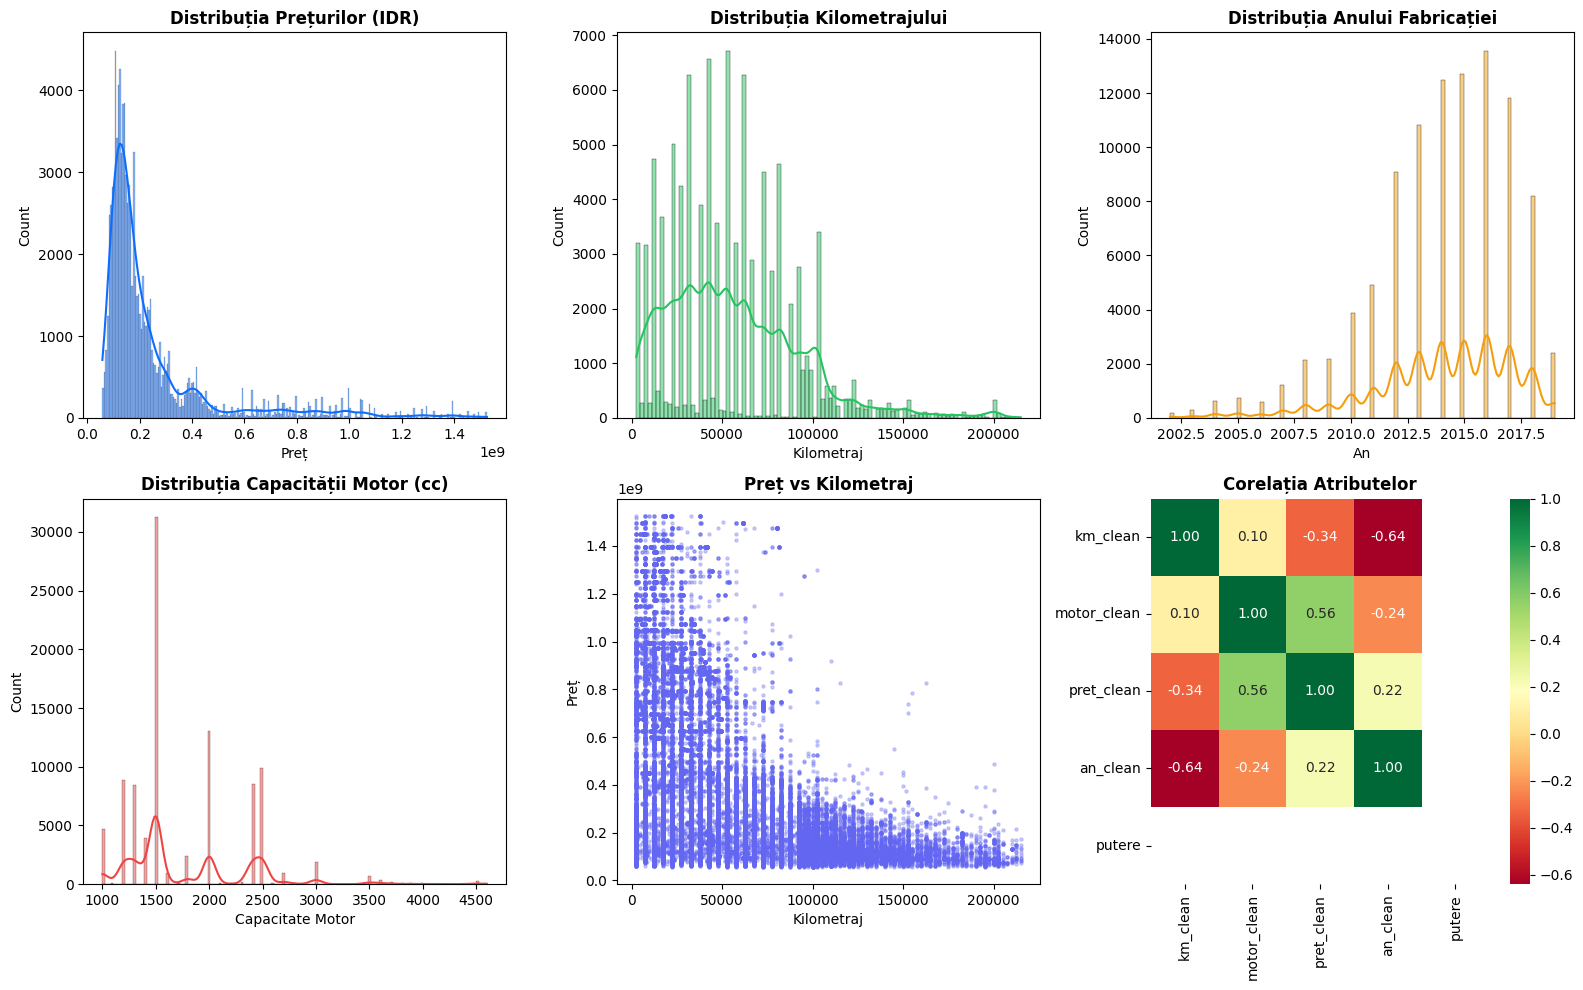


✅ Model KNN NearestNeighbors antrenat!

✅ Etichete clustere: {1: 'Economice', 0: 'Medii', 3: 'Premium Clasice', 2: 'Premium Recente'}

📊══════════════════════════════════════════════════
CLASSIFICATION REPORT - DATE CURATE (referință)
════════════════════════════════════════════════════
                 precision    recall  f1-score   support

          Medii       1.00      1.00      1.00      8966
      Economice       1.00      1.00      1.00      4925
Premium Recente       0.99      0.99      0.99      1624
Premium Clasice       0.99      0.99      0.99      4041

       accuracy                           1.00     19556
      macro avg       0.99      0.99      0.99     19556
   weighted avg       1.00      1.00      1.00     19556

📊══════════════════════════════════════════════════
CLASSIFICATION REPORT - DATE CU ZGOMOT (realist)
════════════════════════════════════════════════════
                 precision    recall  f1-score   support

          Medii       0.84      0.72    

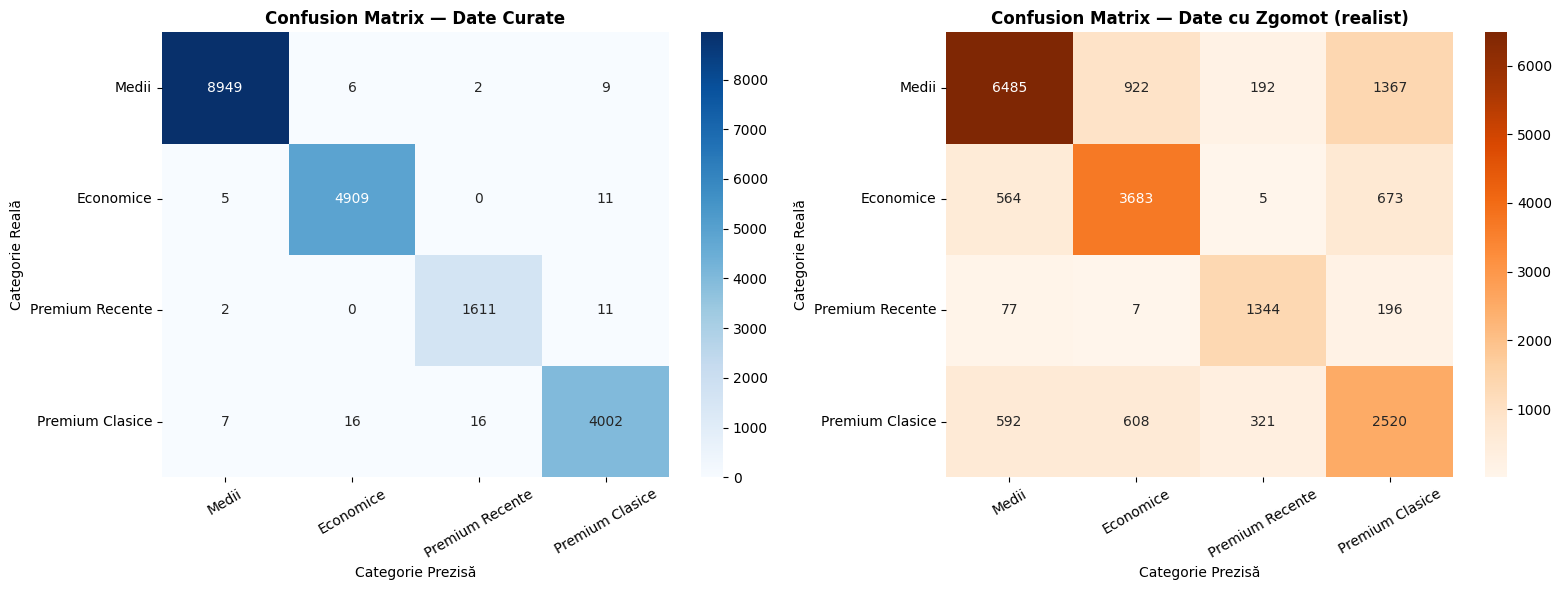

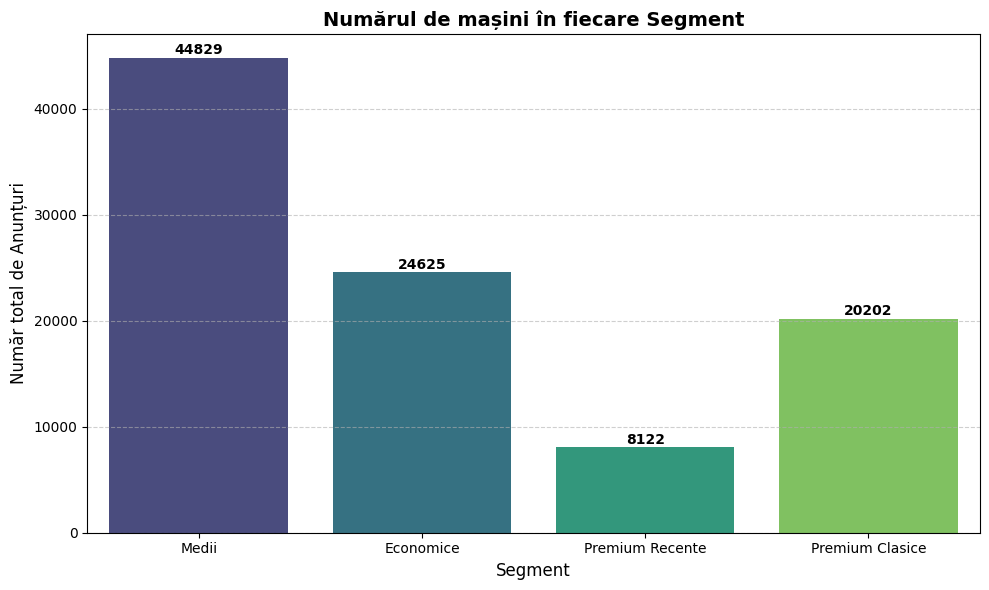

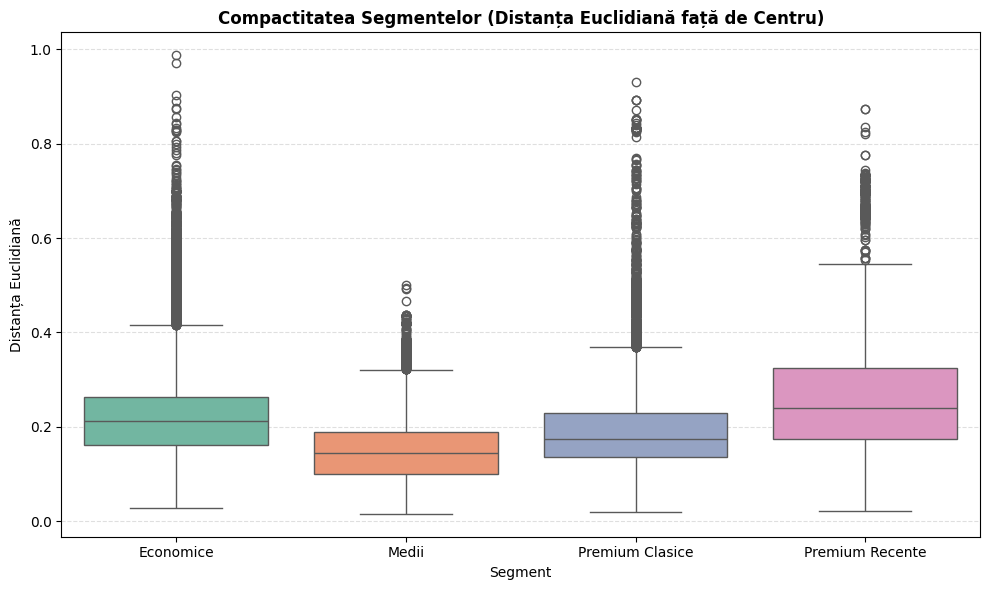


📦══════════════════════════════════════════════════
CONFIGURAȚIE EXPORTATĂ PENTRU C# (appsettings.json)
════════════════════════════════════════════════════
{
    "KNNSettings": {
        "MinValues": [
            2500.0,
            1000.0,
            58000000.0,
            2002.0,
            250.0
        ],
        "MaxValues": [
            215000.0,
            4600.0,
            1525000000.0,
            2019.0,
            250.0
        ],
        "DatasetSampleCount": 97778,
        "AccuracyFaraZgomot": 0.9957,
        "AccuracyCuZgomot": 0.7175
    }
}


In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import io
import re
import json
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════
# 1. FUNCȚII PARSARE
# ══════════════════════════════════════════════
def parse_mileage(val):
    val = str(val).lower().replace(' ', '')
    if re.search(r'(\d+)-k', val):
        n = int(re.search(r'(\d+)-k', val).group(1))
        return n * 1000
    m = re.search(r'(\d+)-(\d+)k', val)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2 * 1000
    n = re.search(r'(\d+)', val)
    return int(n.group(1)) * 1000 if n else np.nan

def parse_eng(val):
    try:
        return float(str(val).replace(',', '.')) * 1000
    except:
        return np.nan

def parse_price_mobil(val):
    try:
        return float(str(val).replace(',', ''))
    except:
        return np.nan

def parse_hp(val):
    val = str(val).lower().replace(' ', '')
    m = re.search(r'(\d+)-(\d+)', val)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    n = re.search(r'(\d+)', val)
    return float(n.group(1)) if n else np.nan

# ══════════════════════════════════════════════
# 2. ÎNCĂRCARE DATE
# ══════════════════════════════════════════════
print("🔵 Pasul 1: Uploadează mobil123.csv")
uploaded1 = files.upload()
df1 = pd.read_csv(io.BytesIO(list(uploaded1.values())[0]), low_memory=False)

print("\n🔵 Pasul 2: Uploadează CarsDatasets2025.csv")
uploaded2 = files.upload()
df2 = pd.read_csv(io.BytesIO(list(uploaded2.values())[0]), encoding='latin-1')

# ══════════════════════════════════════════════
# 3. PROCESARE ȘI MERGE
# ══════════════════════════════════════════════
df1['km_clean']    = df1['mileage'].apply(parse_mileage)
df1['motor_clean'] = df1['engV'].apply(parse_eng)
df1['pret_clean']  = df1['price'].apply(parse_price_mobil)
df1['an_clean']    = pd.to_numeric(df1['year'], errors='coerce')

df2['putere_clean'] = df2['HorsePower'].apply(parse_hp)
putere_medie = df2['putere_clean'].median()

df_ml = df1[['km_clean', 'motor_clean', 'pret_clean', 'an_clean']].copy()
df_ml['putere'] = putere_medie
df_ml = df_ml.dropna()

for col in df_ml.columns:
    q_low  = df_ml[col].quantile(0.01)
    q_high = df_ml[col].quantile(0.99)
    df_ml  = df_ml[(df_ml[col] >= q_low) & (df_ml[col] <= q_high)]

print(f"\n✅ Dataset pregătit. Rânduri: {df_ml.shape[0]}")

# ══════════════════════════════════════════════
# 4. EDA - ANALIZA VIZUALĂ
# ══════════════════════════════════════════════
print("\n📊 EDA — Distribuții și Corelații")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Histograme
sns.histplot(df_ml['pret_clean'], kde=True, color='#0d6efd', ax=axes[0, 0])
axes[0, 0].set_title('Distribuția Prețurilor (IDR)', fontweight='bold')
axes[0, 0].set_xlabel('Preț')

sns.histplot(df_ml['km_clean'], kde=True, color='#22c55e', ax=axes[0, 1])
axes[0, 1].set_title('Distribuția Kilometrajului', fontweight='bold')
axes[0, 1].set_xlabel('Kilometraj')

sns.histplot(df_ml['an_clean'], kde=True, color='#f59e0b', ax=axes[0, 2])
axes[0, 2].set_title('Distribuția Anului Fabricației', fontweight='bold')
axes[0, 2].set_xlabel('An')

sns.histplot(df_ml['motor_clean'], kde=True, color='#ef4444', ax=axes[1, 0])
axes[1, 0].set_title('Distribuția Capacității Motor (cc)', fontweight='bold')
axes[1, 0].set_xlabel('Capacitate Motor')

# Scatter Preț vs Kilometraj
axes[1, 1].scatter(df_ml['km_clean'], df_ml['pret_clean'],
                   alpha=0.3, s=5, color='#6366f1')
axes[1, 1].set_title('Preț vs Kilometraj', fontweight='bold')
axes[1, 1].set_xlabel('Kilometraj')
axes[1, 1].set_ylabel('Preț')

# Heatmap corelații
sns.heatmap(df_ml.corr(), annot=True, cmap='RdYlGn',
            fmt='.2f', ax=axes[1, 2])
axes[1, 2].set_title('Corelația Atributelor', fontweight='bold')

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 5. NORMALIZARE ȘI KNN (Recomandare)
# ══════════════════════════════════════════════
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_ml)

model_recomandare = NearestNeighbors(n_neighbors=5, metric='euclidean')
model_recomandare.fit(X_scaled)
print("\n✅ Model KNN NearestNeighbors antrenat!")

# ══════════════════════════════════════════════
# 6. GENERARE ETICHETE (K-Means)
# ══════════════════════════════════════════════
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
y_clusters = kmeans.fit_predict(X_scaled)
df_ml['cluster'] = y_clusters

# Determinăm etichetele după media prețului per cluster
cluster_means = df_ml.groupby('cluster')['pret_clean'].mean().sort_values()
cluster_labels_map = {}
sorted_clusters = cluster_means.index.tolist()
names = ['Economice', 'Medii', 'Premium Clasice', 'Premium Recente']
for i, cid in enumerate(sorted_clusters):
    cluster_labels_map[cid] = names[i]

target_names_ordered = [cluster_labels_map[i] for i in range(4)]
print(f"\n✅ Etichete clustere: {cluster_labels_map}")

# ══════════════════════════════════════════════
# 7. CLASSIFICATION REPORT & CONFUSION MATRIX
# ══════════════════════════════════════════════
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_clusters, test_size=0.2, random_state=42, stratify=y_clusters
)

knn_classifier = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_classifier.fit(X_train, y_train)
y_pred = knn_classifier.predict(X_test)

# ── Date curate ──
print("\n📊" + "═" * 50)
print("CLASSIFICATION REPORT - DATE CURATE (referință)")
print("═" * 52)
print(classification_report(y_test, y_pred, target_names=target_names_ordered))

# ── Date cu zgomot (evaluare realistă) ──
np.random.seed(42)
X_test_noisy = X_test + np.random.normal(0, 0.15, X_test.shape)
y_pred_noisy = knn_classifier.predict(X_test_noisy)

print("📊" + "═" * 50)
print("CLASSIFICATION REPORT - DATE CU ZGOMOT (realist)")
print("═" * 52)
print(classification_report(y_test, y_pred_noisy, target_names=target_names_ordered))

acc_clean = (y_pred == y_test).mean()
acc_noisy = (y_pred_noisy == y_test).mean()
print(f"Accuracy fără zgomot: {acc_clean:.4f}")
print(f"Accuracy cu zgomot:   {acc_noisy:.4f}")
print(f"Degradare:            {(acc_clean - acc_noisy):.4f}")

# ── Confusion Matrix ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_clean = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_clean, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names_ordered,
            yticklabels=target_names_ordered, ax=axes[0])
axes[0].set_title('Confusion Matrix — Date Curate', fontweight='bold')
axes[0].set_ylabel('Categorie Reală')
axes[0].set_xlabel('Categorie Prezisă')
axes[0].tick_params(axis='x', rotation=30)

cm_noisy = confusion_matrix(y_test, y_pred_noisy)
sns.heatmap(cm_noisy, annot=True, fmt='d', cmap='Oranges',
            xticklabels=target_names_ordered,
            yticklabels=target_names_ordered, ax=axes[1])
axes[1].set_title('Confusion Matrix — Date cu Zgomot (realist)', fontweight='bold')
axes[1].set_ylabel('Categorie Reală')
axes[1].set_xlabel('Categorie Prezisă')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 8. BAR CHART - DISTRIBUȚIA PE SEGMENTE
# ══════════════════════════════════════════════
cluster_counts = df_ml['cluster'].value_counts().sort_index()
cluster_labels_list = [cluster_labels_map[i] for i in cluster_counts.index]

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=cluster_labels_list, y=cluster_counts.values,
                 palette='viridis', hue=cluster_labels_list, legend=False)
plt.title('Numărul de mașini în fiecare Segment',
          fontsize=14, fontweight='bold')
plt.xlabel('Segment', fontsize=12)
plt.ylabel('Număr total de Anunțuri', fontsize=12)

for i, v in enumerate(cluster_counts.values):
    plt.text(i, v + 10, str(v), ha='center', va='bottom',
             fontweight='bold', color='black')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 9. BOXPLOT COMPACTITATE SEGMENTE
# ══════════════════════════════════════════════
X_centers = kmeans.cluster_centers_
distante = np.sqrt(np.sum((X_scaled - X_centers[y_clusters]) ** 2, axis=1))
df_ml['distanta_centru'] = distante
df_ml['cluster_label'] = df_ml['cluster'].map(cluster_labels_map)

plt.figure(figsize=(10, 6))
sns.boxplot(x='cluster_label', y='distanta_centru',
            data=df_ml, palette='Set2',
            order=['Economice', 'Medii', 'Premium Clasice', 'Premium Recente'])
plt.title('Compactitatea Segmentelor (Distanța Euclidiană față de Centru)',
          fontweight='bold')
plt.xlabel('Segment')
plt.ylabel('Distanța Euclidiană')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════
# 10. EXPORT CONFIGURAȚIE C#
# ══════════════════════════════════════════════
min_vals = df_ml.drop(columns=['cluster', 'distanta_centru',
                                'cluster_label']).min().to_dict()
max_vals = df_ml.drop(columns=['cluster', 'distanta_centru',
                                'cluster_label']).max().to_dict()

config_ml = {
    "KNNSettings": {
        "MinValues": list(min_vals.values()),
        "MaxValues": list(max_vals.values()),
        "DatasetSampleCount": len(df_ml),
        "AccuracyFaraZgomot": round(float(acc_clean), 4),
        "AccuracyCuZgomot":   round(float(acc_noisy), 4)
    }
}

print("\n📦" + "═" * 50)
print("CONFIGURAȚIE EXPORTATĂ PENTRU C# (appsettings.json)")
print("═" * 52)
print(json.dumps(config_ml, indent=4))